# Встреча 3. Запуск и доверие к данным: практика

> **Время:** 55 минут · **Опирается на:** `theory.ipynb` · **Данные:** `../data/checkout_ab.csv`, `../data/srm_case_{1..5}.csv`, `../data/telemetry_ab.csv`

**Легенда.** Тест нового чекаута отработал 14 дней по дизайн-доку встречи 2: сплит 80/20, ~105 тыс. пользователей. Владелец продукта ждёт эффект, но сначала вы отвечаете за данные: можно ли им верить. Параллельно платформа прислала пять тестов других команд с тревогой SRM и тест виджета доставки, где «что-то не так с событиями». Итог — чек-лист запуска, по которому команда будет проверять каждый следующий тест.

| № | Задание | Минут |
| :---: | --- | :---: |
| 1 | Качество выгрузки чекаута: дубли и пользователи в обеих группах | 10 |
| 2 | SRM против 80/20: весь тест и по дням | 10 |
| 3 | SRM-детектив: пять выгрузок — пять причин | 20 |
| 4 | Телеметрия: потери событий, ITT против триггера, разбавление | 10 |
| 5 | Чек-лист запуска для чекаута | 5 |

Формат: задание → ячейка `# ВАШ КОД` → свёрнутое решение → ячейка «Проверка» с `assert`.

* **Свой код проверяйте так:** запустите свою ячейку, затем сразу «Проверку», пропустив ячейку решения.
* **Решение перезаписывает ваши переменные и функции.** Поэтому не нажимайте Run All, если проверяете своё: он выполнит решения поверх вашего кода. На незаполненной заглушке Run All остановится с `NotImplementedError`.
* **Застряли больше 5 минут** — запустите решение: дальше ноутбук опирается на его переменные.

## 0. Подготовка

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data')
SALT, SHARE_B = 'checkout-v2', 0.20


def assign_group(user_id, salt: str = SALT, share_b: float = SHARE_B) -> str:
    """Назначение группы платформой: md5(соль:user_id) → бакет 0..9999 → B, если бакет < 2000."""
    h = int(hashlib.md5(f'{salt}:{user_id}'.encode()).hexdigest(), 16)
    return 'B' if h % 10_000 < share_b * 10_000 else 'A'


def spaced(value: float) -> str:
    return f'{value:,.0f}'.replace(',', ' ')


raw = pd.read_csv(DATA / 'checkout_ab.csv')
print(f'Строк: {spaced(len(raw))}; уникальных user_id: {spaced(raw.user_id.nunique())}')
raw.head()

Строк: 105 330; уникальных user_id: 105 020


,user_id,date,group,converted,revenue,checkout_time_sec,payment_error,orders_prev28,revenue_prev28
0,7480367,2026-09-20,A,1,997.12,261.9,0,2,3817.54
1,9280410,2026-09-12,A,1,23649.07,55.2,0,7,109549.40
2,5231080,2026-09-16,B,1,1719.31,17.5,0,1,2166.69
3,9684298,2026-09-13,A,1,2037.39,123.9,0,2,3051.12
4,1961867,2026-09-12,A,1,1761.46,45.4,0,2,2938.46


## Задание 1. Качество выгрузки (10 минут)

Строк больше, чем уникальных пользователей. Найдите две проблемы лога:

1. `n_duplicates` — число **полных** дублей строк (событие записалось дважды);
2. `n_users_both` — число пользователей, у которых после удаления дублей есть записи в **обеих** группах;
3. `checkout` — очищенная таблица: полные дубли схлопнуты, пользователи из обеих групп исключены **целиком**; индекс сброшен.

Дополнительно проверьте, совпадает ли группа в логе с `assign_group(user_id)`: сколько строк расходится до и после очистки (`mismatch_raw`, `mismatch_clean`).

In [2]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [3]:
# @title Решение (нажмите, чтобы раскрыть)
n_duplicates = int(raw.duplicated().sum())
dedup = raw.drop_duplicates()
groups_per_user = dedup.groupby('user_id')['group'].nunique()
users_both = groups_per_user[groups_per_user > 1].index
n_users_both = len(users_both)
checkout = dedup[~dedup['user_id'].isin(users_both)].reset_index(drop=True)

hashed = raw['user_id'].map(assign_group)
mismatch_raw = int((raw['group'] != hashed).sum())
mismatch_clean = int((checkout['group'] != checkout['user_id'].map(assign_group)).sum())

print(f'Полных дублей: {n_duplicates}; пользователей в обеих группах: {n_users_both}')
print(f'Строк: {spaced(len(raw))} → {spaced(len(checkout))}; группа ≠ хеш: до {mismatch_raw}, после {mismatch_clean}')

Полных дублей: 250; пользователей в обеих группах: 60
Строк: 105 330 → 104 960; группа ≠ хеш: до 60, после 0


**Проверка.** 250 дублей, 60 пользователей в обеих группах; после очистки один пользователь — одна строка, и группа всегда совпадает с хешем.

In [4]:
# Проверка
assert n_duplicates == 250, 'Полные дубли: raw.duplicated().sum()'
assert n_users_both == 60, 'Считайте пользователей с двумя группами ПОСЛЕ удаления дублей'
assert len(checkout) == 104_960 and checkout['user_id'].is_unique, 'Исключите пользователей из обеих групп целиком (обе их строки)'
assert mismatch_raw == 60 and mismatch_clean == 0
print('Задание 1 принято')

Задание 1 принято


**Вопрос.** Почему дубли просто схлопываем, а пользователей из обеих групп исключаем целиком, а не оставляем запись, совпадающую с хешем? Когда такое исключение опасно?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Дубль** — одна и та же строка дважды: информации в ней нет, `drop_duplicates()` ничего не теряет. Если не схлопнуть, 250 пользователей посчитаются дважды, а дисперсия занизится.

**Пользователь в обеих группах** — мы не знаем, что он видел: старый чекаут, новый или оба. Его метрики теста относятся к смеси вариантов. Запись «по хешу» оставлять нельзя: мы знаем, куда его *назначили*, но не что ему *показали*. Исключаем целиком.

Опасно, когда таких много или они перекошены по группам: если баг бьёт только по B (скажем, по одной версии приложения), исключение меняет состав B, и рандомизация ломается. Поэтому после любой очистки — снова SRM (задание 2). У нас 60 пользователей — 0.06%, на результат это не влияет, но причину (рассинхрон логирования с назначением) надо передать платформе.
</details>

<details>
<summary><b>А если ITT?</b> (нажмите, чтобы раскрыть)</summary>

Строго по ITT пользователя оставляют в группе назначения (по хешу) с его метриками. Это честно по отношению к рандомизации, но разбавляет эффект смешанными пользователями. При 0.06% обе стратегии дают одно и то же; при заметной доле считайте обе и пишите об этом в отчёте.
</details>

## Задание 2. SRM против 80/20 (10 минут)

1. Напишите `srm_test(counts, shares)` — p-value критерия согласия $\chi^2$: наблюдаемые размеры групп `counts` против плана `shares` (доли, в сумме 1).
2. `srm_p` — p-value SRM очищенного `checkout` против 80/20.
3. `daily` — таблица по дням (индекс — `date`) с колонками `n`, `share_b`, `p_value` (SRM каждого дня против 80/20).

In [5]:
def srm_test(counts, shares) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [6]:
# @title Решение (нажмите, чтобы раскрыть)
def srm_test(counts, shares) -> float:
    counts = np.asarray(counts, dtype=float)
    return float(stats.chisquare(counts, counts.sum() * np.asarray(shares, dtype=float)).pvalue)


group_counts = checkout['group'].value_counts().reindex(['A', 'B'], fill_value=0)
srm_p = srm_test(group_counts, [0.8, 0.2])
daily = checkout.groupby('date')['group'].agg(
    n='size',
    share_b=lambda g: (g == 'B').mean(),
    p_value=lambda g: srm_test([(g == 'A').sum(), (g == 'B').sum()], [0.8, 0.2]),
)
print(f"A: {spaced(group_counts['A'])}, B: {spaced(group_counts['B'])}, доля B = {group_counts['B'] / group_counts.sum():.4f}, SRM p = {srm_p:.3f}")
daily.round(4)

A: 83 878, B: 21 082, доля B = 0.2009, SRM p = 0.487


,n,share_b,p_value
date,,,
2026-09-07,7406,0.2047,0.3120
2026-09-08,7545,0.1963,0.4203
2026-09-09,7541,0.1975,0.5804
2026-09-10,7505,0.1987,0.7729
2026-09-11,7402,0.1959,0.3770
2026-09-12,7500,0.1995,0.9081
2026-09-13,7577,0.2014,0.7608
2026-09-14,7531,0.1969,0.5039
2026-09-15,7490,0.2049,0.2852


**Проверка.** SRM на всём тесте нет; самый «подозрительный» день и общий порог сверяем с `scipy`.

In [7]:
# Проверка
assert abs(srm_test([800, 200], [0.8, 0.2]) - 1.0) < 1e-12
assert abs(srm_test([830, 170], [0.8, 0.2]) - stats.binomtest(170, 1000, 0.2).pvalue) < 0.01
assert abs(srm_p - 0.4874) < 1e-3, 'SRM очищенных данных против 80/20 (не против 50/50!)'
assert daily.shape[0] == 14 and {'n', 'share_b', 'p_value'} <= set(daily.columns)
assert abs(daily['p_value'].min() - 0.0319) < 1e-3 and daily['p_value'].idxmin() == '2026-09-20'
print('Задание 2 принято')

Задание 2 принято


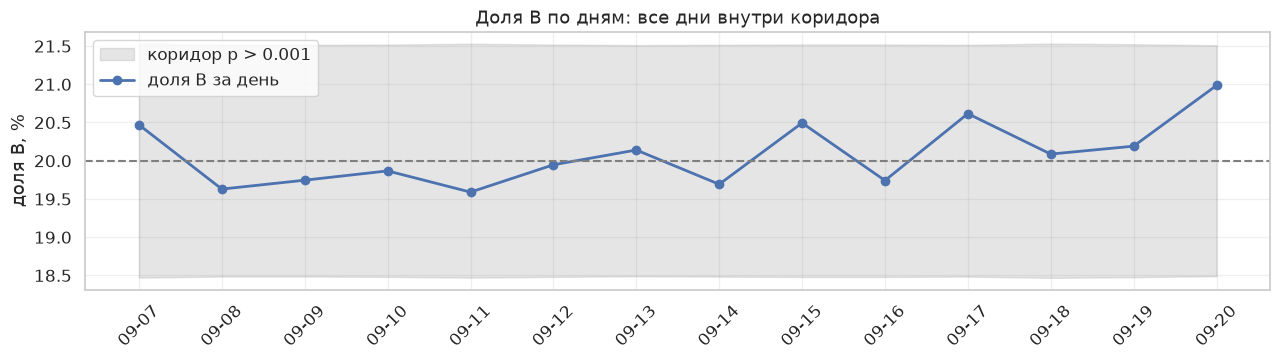

In [8]:
fig, ax = plt.subplots(figsize=(13, 3.8))
se = np.sqrt(0.2 * 0.8 / daily['n'])
ax.fill_between(range(len(daily)), (0.2 - 3.29 * se) * 100, (0.2 + 3.29 * se) * 100, color=GRAY, alpha=0.2, label='коридор p > 0.001')
ax.plot(range(len(daily)), daily['share_b'] * 100, 'o-', color=BLUE, linewidth=2, label='доля B за день')
ax.axhline(20, color=GRAY, linestyle='--')
ax.set_xticks(range(len(daily)))
ax.set_xticklabels([d[5:] for d in daily.index], rotation=45)
ax.set_ylabel('доля B, %')
ax.set_title('Доля B по дням: все дни внутри коридора')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Вопрос.** В последний день $p = 0.032$. Это SRM? Что сказать, если владелец продукта увидит этот день на дашборде?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Мы сделали 14 проверок: хотя бы одна с $p < 0.05$ при исправном сплите выпадает с вероятностью $1 - 0.95^{14} \approx 51\%$. С поправкой Бонферрони это $p = 0.032 \times 14 = 0.45$; да и порог SRM — 0.001, а не 0.05. Доля B в этот день — 21.0% при коридоре ±3.3σ ≈ ±1.5 п.п.

Ответ владельцу: «Сплит в норме и в целом ($p = 0.49$), и в каждый день. Мелкие колебания доли по дням — шум». Если бы день был за коридором — смотрели бы, что в этот день случилось (релиз, акция, сбой логирования).
</details>

## Задание 3. SRM-детектив (20 минут)

Платформа прислала пять тестов с тревогой SRM. Все — сплит 80/20, 14 дней. Колонки: `user_id`, `date`, `group`, `device` (ios / android / web), `source` (organic / ads / push / email), `is_bot` (антифрод пометил ботом), `lag_sec` (секунд от назначения до первого события теста в логе), `converted`. Платформа считает тест по строкам с `is_bot == 0`.

1. Напишите `srm_by(df, col)` — таблица по значениям `col`: `n`, `share_b`, `p_value` (SRM против 80/20 внутри среза).
2. Для каждого кейса найдите срез, где сидит дисбаланс. Смотрите: по дням, по устройствам, по источникам, с ботами и без, распределение `lag_sec` по группам.
3. Заполните `diagnosis = {1: ..., 2: ..., 3: ..., 4: ..., 5: ...}` кодами причин:

| Код | Причина |
| --- | --- |
| `'assignment_bug'` | баг назначения |
| `'bot_filter'` | ботфильтр / антифрод после назначения |
| `'telemetry_loss'` | потери телеметрии в одной группе |
| `'redirect'` | триггер / редирект только в одной ветке |
| `'start_date'` | неверная дата старта / кэш |

Каждая причина встречается ровно один раз.

In [9]:
cases = {k: pd.read_csv(DATA / f'srm_case_{k}.csv') for k in range(1, 6)}
for k, df in cases.items():
    humans = df[df['is_bot'] == 0]
    print(f"Кейс {k}: {spaced(len(df))} строк, доля B без ботов = {(humans['group'] == 'B').mean():.4f}")
cases[1].head()

Кейс 1: 29 901 строк, доля B без ботов = 0.1758
Кейс 2: 30 926 строк, доля B без ботов = 0.1826
Кейс 3: 30 975 строк, доля B без ботов = 0.1898
Кейс 4: 30 855 строк, доля B без ботов = 0.1610
Кейс 5: 30 412 строк, доля B без ботов = 0.1895


,user_id,date,group,device,source,is_bot,lag_sec,converted
0,94127475,2026-09-07,A,ios,organic,0,17.2,1
1,91536574,2026-09-07,A,android,email,0,16.7,0
2,28168014,2026-09-07,A,ios,push,0,29.6,0
3,50974619,2026-09-09,A,ios,ads,0,15.7,0
4,70288271,2026-09-16,A,web,ads,0,11.1,0


In [10]:
def srm_by(df: pd.DataFrame, col: str) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError


diagnosis = {}   # ВАШ КОД: {номер кейса: код причины}
raise NotImplementedError

NotImplementedError: 

In [11]:
# @title Решение (нажмите, чтобы раскрыть)
def srm_by(df: pd.DataFrame, col: str) -> pd.DataFrame:
    return df.groupby(col)['group'].agg(
        n='size',
        share_b=lambda g: (g == 'B').mean(),
        p_value=lambda g: srm_test([(g == 'A').sum(), (g == 'B').sum()], [0.8, 0.2]),
    )


def investigate(k: int) -> None:
    df = cases[k]
    humans = df[df['is_bot'] == 0]
    print(f"===== Кейс {k}: SRM без ботов p = {srm_test(humans['group'].value_counts().reindex(['A', 'B']), [0.8, 0.2]):.1e}, "
          f"со всеми строками p = {srm_test(df['group'].value_counts().reindex(['A', 'B']), [0.8, 0.2]):.1e}")
    print('доля ботов по группам:', df.groupby('group')['is_bot'].mean().round(3).to_dict())
    for col in ['device', 'source']:
        print(srm_by(humans, col).round(4).T.to_string(), '\n')
    print('доля B по дням:', srm_by(humans, 'date')['share_b'].round(3).tolist())
    print('lag_sec по группам (квантили 1%, 50%, 99%):')
    print(humans.groupby('group')['lag_sec'].quantile([0.01, 0.5, 0.99]).unstack().round(1).to_string(), '\n')


for k in cases:
    investigate(k)

diagnosis = {1: 'redirect', 2: 'start_date', 3: 'bot_filter', 4: 'assignment_bug', 5: 'telemetry_loss'}

===== Кейс 1: SRM без ботов p = 5.4e-25, со всеми строками p = 5.0e-28
доля ботов по группам: {'A': 0.031, 'B': 0.023}
device      android         ios        web
n        11684.0000  10246.0000  7088.0000
share_b      0.1757      0.1746     0.1775
p_value      0.0000      0.0000     0.0000 



source         ads      email     organic       push
n        7980.0000  4505.0000  11971.0000  4562.0000
share_b     0.1229     0.1905      0.1982     0.1947
p_value     0.0000     0.1092      0.6281     0.3665 

доля B по дням: [0.183, 0.174, 0.174, 0.176, 0.171, 0.17, 0.172, 0.173, 0.177, 0.181, 0.164, 0.195, 0.171, 0.18]
lag_sec по группам (квантили 1%, 50%, 99%):


       0.01  0.50   0.99
group                   
A       2.4  25.2  262.7
B       3.9  25.8  253.4 

===== Кейс 2: SRM без ботов p = 5.1e-14, со всеми строками p = 7.3e-15
доля ботов по группам: {'A': 0.03, 'B': 0.027}
device      android         ios        web
n        12175.0000  10486.0000  7363.0000
share_b      0.1791      0.1862     0.1832
p_value      0.0000      0.0004     0.0003 



source         ads      email     organic       push
n        8666.0000  4573.0000  12151.0000  4634.0000
share_b     0.1837     0.1703      0.1871     0.1811
p_value     0.0001     0.0000      0.0004     0.0013 



доля B по дням: [0.047, 0.126, 0.206, 0.184, 0.212, 0.202, 0.198, 0.193, 0.197, 0.197, 0.201, 0.201, 0.195, 0.193]
lag_sec по группам (квантили 1%, 50%, 99%):
       0.01  0.50   0.99
group                   
A       2.4  24.7  266.2
B       2.3  24.7  284.4 

===== Кейс 3: SRM без ботов p = 1.0e-05, со всеми строками p = 9.2e-01
доля ботов по группам: {'A': 0.03, 'B': 0.093}
device      android         ios        web
n        11925.0000  10481.0000  7243.0000
share_b      0.1931      0.1869     0.1883
p_value      0.0605      0.0008     0.0129 



source         ads      email     organic       push
n        8588.0000  4588.0000  12012.0000  4461.0000
share_b     0.1905     0.1859      0.1899     0.1919
p_value     0.0277     0.0171      0.0056     0.1754 

доля B по дням: [0.189, 0.188, 0.189, 0.188, 0.191, 0.184, 0.2, 0.187, 0.197, 0.174, 0.185, 0.19, 0.203, 0.194]
lag_sec по группам (квантили 1%, 50%, 99%):


       0.01  0.50   0.99
group                   
A       2.4  25.0  246.4
B       2.6  25.1  271.3 

===== Кейс 4: SRM без ботов p = 9.7e-64, со всеми строками p = 1.8e-66
доля ботов по группам: {'A': 0.032, 'B': 0.031}
device      android         ios        web
n        12057.0000  10514.0000  7300.0000
share_b      0.1992      0.0916     0.1978
p_value      0.8305      0.0000     0.6397 



source        ads      email     organic       push
n        8746.000  4499.0000  12027.0000  4599.0000
share_b     0.162     0.1618      0.1611     0.1579
p_value     0.000     0.0000      0.0000     0.0000 

доля B по дням: [0.165, 0.152, 0.166, 0.16, 0.171, 0.164, 0.155, 0.152, 0.165, 0.162, 0.156, 0.158, 0.171, 0.157]
lag_sec по группам (квантили 1%, 50%, 99%):
       0.01  0.50   0.99
group                   
A       2.5  25.0  253.3
B       2.4  25.1  269.0 

===== Кейс 5: SRM без ботов p = 6.3e-06, со всеми строками p = 6.6e-06


доля ботов по группам: {'A': 0.03, 'B': 0.032}
device      android         ios        web
n        11949.0000  10376.0000  7156.0000
share_b      0.1883      0.1936     0.1854
p_value      0.0014      0.1042     0.0021 

source         ads      email     organic       push
n        8556.0000  4461.0000  11963.0000  4501.0000
share_b     0.1918     0.1910      0.1898     0.1828
p_value     0.0578     0.1324      0.0051     0.0040 



доля B по дням: [0.19, 0.183, 0.18, 0.189, 0.197, 0.192, 0.19, 0.192, 0.184, 0.192, 0.186, 0.195, 0.199, 0.183]
lag_sec по группам (квантили 1%, 50%, 99%):
       0.01   0.50    0.99
group                     
A       2.4   24.7   269.9
B      37.0  897.4  3446.4 



**Проверка.** Ответы зашифрованы хешем: ячейка скажет, какие кейсы не сошлись, но не подскажет правильный ответ.

In [12]:
# Проверка
ios = srm_by(cases[4][cases[4]['is_bot'] == 0], 'device').loc['ios']
assert abs(ios['share_b'] - 0.0916) < 1e-3 and ios['p_value'] < 1e-10, 'srm_by: доля B и p-value внутри каждого среза'
assert sorted(diagnosis) == [1, 2, 3, 4, 5], 'Нужен диагноз для всех пяти кейсов'
assert len(set(diagnosis.values())) == 5, 'Каждая причина встречается ровно один раз'
EXPECTED = {1: 'b888fed891e5', 2: '68d8783cdcf2', 3: 'bdad80230a73', 4: '254b21f33ac2', 5: '302826c8a43b'}
wrong = [k for k, cause in diagnosis.items() if hashlib.md5(f'{k}:{cause}'.encode()).hexdigest()[:12] != EXPECTED[k]]
assert not wrong, f'Не сошлись кейсы {wrong}: посмотрите срезы по дням, устройствам, источникам, ботам и lag_sec'
print('Задание 3 принято')

Задание 3 принято


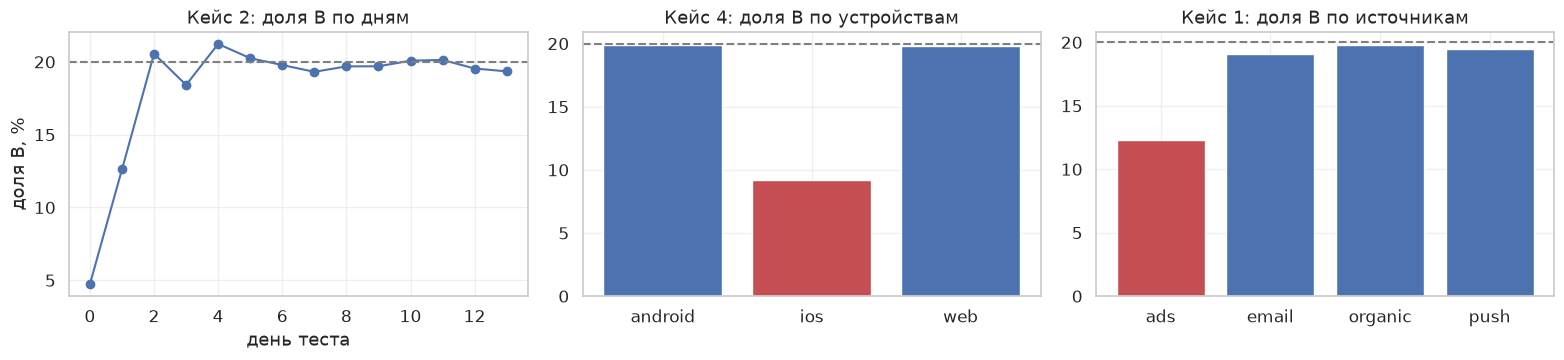

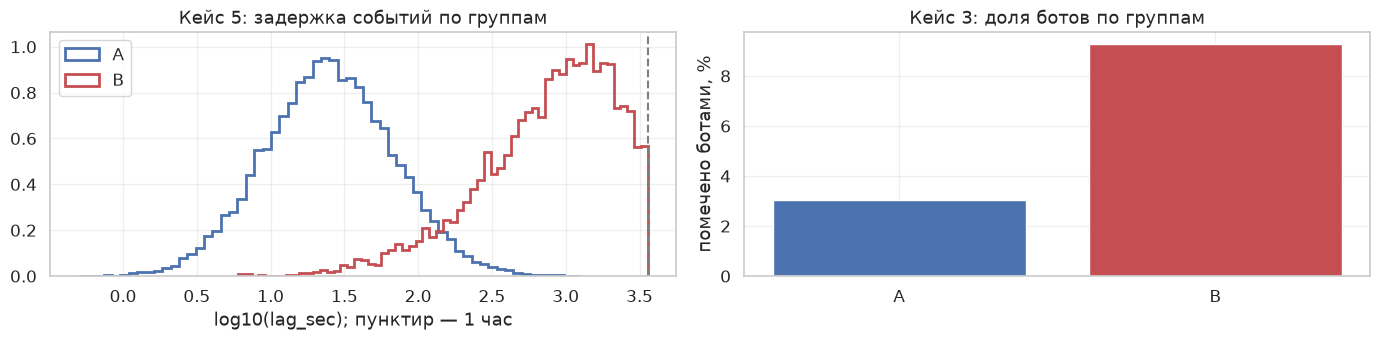

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
day_share = srm_by(cases[2][cases[2]['is_bot'] == 0], 'date')['share_b']
axes[0].plot(range(len(day_share)), day_share * 100, 'o-', color=BLUE)
axes[0].axhline(20, color=GRAY, linestyle='--')
axes[0].set_title('Кейс 2: доля B по дням')
axes[0].set_xlabel('день теста')
axes[0].set_ylabel('доля B, %')
for k, ax, col, title in [(4, axes[1], 'device', 'Кейс 4: доля B по устройствам'), (1, axes[2], 'source', 'Кейс 1: доля B по источникам')]:
    share = srm_by(cases[k][cases[k]['is_bot'] == 0], col)['share_b']
    ax.bar(share.index, share * 100, color=[RED if v < 0.17 else BLUE for v in share])
    ax.axhline(20, color=GRAY, linestyle='--')
    ax.set_title(title)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
humans = cases[5][cases[5]['is_bot'] == 0]
for group, color in [('A', BLUE), ('B', RED)]:
    axes[0].hist(np.log10(humans.loc[humans['group'] == group, 'lag_sec']), bins=60, density=True, histtype='step', linewidth=2, color=color, label=group)
axes[0].axvline(np.log10(3600), color=GRAY, linestyle='--')
axes[0].set_xlabel('log10(lag_sec); пунктир — 1 час')
axes[0].set_title('Кейс 5: задержка событий по группам')
axes[0].legend()
bots = cases[3].groupby('group')['is_bot'].mean() * 100
axes[1].bar(bots.index, bots, color=[BLUE, RED])
axes[1].set_ylabel('помечено ботами, %')
axes[1].set_title('Кейс 3: доля ботов по группам')
plt.tight_layout()
plt.show()

**Разбор.** Что выдаёт каждую причину.

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

| Кейс | Причина | Признак | Что делать |
| :---: | --- | --- | --- |
| 1 | Редирект только в B | Дефицит B только в `source = ads` (12% вместо 20%); у B `lag_sec` на ~1.5 с больше — лишний переход | Рендерить вариант на том же URL или логировать назначение до редиректа |
| 2 | Дата старта / кэш | Доля B ~5% в первый день, ~13% во второй, дальше 20%; по устройствам и источникам дефицит равномерный | Считать с фактического включения (с третьего дня); при старте сбрасывать кэш |
| 3 | Ботфильтр после назначения | Со всеми строками сплит честный ($p = 0.92$); ботов 3% в A и 9% в B | Фильтровать ботов по признакам до назначения, проверять SRM до и после фильтра |
| 4 | Баг назначения | На iOS доля B 9%, на android и web — 20%; A больше плана — пользователи перетекли | Чинить SDK: при ошибке исключать из теста, а не класть в контроль |
| 5 | Потери телеметрии | У B задержка событий — минуты, обрыв ровно на 3600 с; дефицит равномерный по срезам | Слать событие с сервера; окно пайплайна больше максимального лага |

Общий приём: сначала со всеми строками и без фильтров, затем срезы по времени, по сегментам, по задержке. Срез, где дисбаланс сидит, почти всегда называет причину. Ни в одном из пяти тестов эффект считать нельзя, пока причина не устранена или не найдена честная подвыборка (например, кейс 2 с третьего дня).
</details>

## Задание 4. Телеметрия: ITT против триггера (10 минут)

Тест нового виджета выбора слота доставки, сплит 50/50, 7 дней, `../data/telemetry_ab.csv`. Виджет видят только пользователи с курьерской доставкой в корзине. Колонки:

* `triggered` — серверный флаг «должен увидеть виджет», одинаковый в обеих группах;
* `exposure_logged` — клиентское событие показа (в A — «показали бы»), часть событий теряется;
* `converted` — заказ по серверу, без потерь.

Посчитайте (эффекты — разница конверсий B − A в **п.п.**):

1. `loss` — `pd.Series` по группам: доля пользователей с `triggered == 1`, у которых нет `exposure_logged`;
2. `itt` — эффект по всем назначенным;
3. `trig` — эффект среди `triggered == 1`;
4. `client` — эффект среди `exposure_logged == 1`;
5. `share_triggered` — доля затронутых и `dilution = 1 / share_triggered` — во сколько раз разбавлен эффект в ITT.

In [14]:
tele = pd.read_csv(DATA / 'telemetry_ab.csv')
tele.groupby('group')[['triggered', 'exposure_logged', 'converted']].mean().round(4)

,triggered,exposure_logged,converted
group,,,
A,0.2496,0.2454,0.3236
B,0.2508,0.2252,0.3311


In [15]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [16]:
# @title Решение (нажмите, чтобы раскрыть)
def effect_pp(df: pd.DataFrame) -> tuple:
    """Разница конверсий B − A в п.п., её SE и p-value z-теста."""
    a, b = df.loc[df['group'] == 'A', 'converted'], df.loc[df['group'] == 'B', 'converted']
    delta = b.mean() - a.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    return delta * 100, se * 100, 2 * stats.norm.sf(abs(delta / se))


triggered_users = tele[tele['triggered'] == 1]
loss = 1 - triggered_users.groupby('group')['exposure_logged'].mean()
itt, se_itt, p_itt = effect_pp(tele)
trig, se_trig, p_trig = effect_pp(triggered_users)
client, se_client, p_client = effect_pp(tele[tele['exposure_logged'] == 1])
share_triggered = tele['triggered'].mean()
dilution = 1 / share_triggered

print('Потеря событий среди затронутых:', loss.round(3).to_dict())
print((1 - triggered_users.groupby(['group', 'device'])['exposure_logged'].mean()).unstack().round(3).to_string(), '\n')
for name, (d, s, p) in {'ITT (все назначенные)': (itt, se_itt, p_itt), 'честный триггер': (trig, se_trig, p_trig),
                        'по клиентскому событию': (client, se_client, p_client)}.items():
    print(f'{name:24s} {d:+.2f} п.п. ± {1.96 * s:.2f}  p = {p:.1e}')
print(f'\nДоля затронутых {share_triggered:.3f} → разбавление в {dilution:.1f} раза')
print(f'Триггер × доля = {trig * share_triggered:+.2f} п.п. ± {1.96 * se_trig * share_triggered:.2f} (сравните с ITT {itt:+.2f} ± {1.96 * se_itt:.2f})')

Потеря событий среди затронутых: {'A': 0.017, 'B': 0.102}
device  android    ios    web
group                        
A         0.018  0.019  0.012
B         0.233  0.023  0.014 

ITT (все назначенные)    +0.75 п.п. ± 0.77  p = 5.7e-02
честный триггер          +3.06 п.п. ± 1.62  p = 2.2e-04
по клиентскому событию   +5.79 п.п. ± 1.68  p = 1.6e-11

Доля затронутых 0.250 → разбавление в 4.0 раза
Триггер × доля = +0.77 п.п. ± 0.41 (сравните с ITT +0.75 ± 0.77)


**Проверка.**

In [17]:
# Проверка
assert abs(loss['A'] - 0.0169) < 1e-3 and abs(loss['B'] - 0.1021) < 1e-3, 'Потеря — среди triggered == 1, по группам'
assert abs(itt - 0.752) < 0.01 and abs(trig - 3.062) < 0.01, 'Эффекты — в п.п. (×100)'
assert abs(client - 5.785) < 0.01
assert abs(dilution - 4.0) < 0.01
print('Задание 4 принято')

Задание 4 принято


**Вопрос.** Какой эффект виджета писать в отчёт? Почему оценка по клиентскому событию почти вдвое больше триггерной, а SRM по событиям показа — есть?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Эффект на затронутых:** честный триггер, +3.1 п.п. ($p = 0.0002$). Триггер серверный, определён одинаково в обеих группах и до показа виджета.
* **Эффект на всех:** +3.1 × 0.25 ≈ +0.77 п.п. Прямая ITT-оценка (+0.75 п.п., $p = 0.057$) с ней согласуется, но из-за шума 75% незатронутых не значима. Разбавленная оценка триггера уже прямой ITT в 1.9 раза.
* **По клиентскому событию (+5.8 п.п.) — смещено.** В B на android теряется 23% событий показа, и теряются они чаще у тех, кто не купил (виджет падает — пользователь уходит). В B остаются более «успешные» пользователи, и эффект завышен почти вдвое. Это метрический SRM: число залогированных показов в B на 8.5% меньше, чем в A, при равном числе затронутых (проверьте `srm_test` на `exposure_logged == 1` против 50/50).

Кроме метрики, это ещё и **guardrail-сигнал**: виджет падает у четверти android-пользователей. Это баг продукта, его чинят до решения о раскатке.
</details>

## Задание 5. Чек-лист запуска для чекаута (5 минут)

Откройте шаблон `launch_checklist.md` (в папке встречи): 15 проверок с порогами — до старта, в первые 48 часов и перед анализом. Для чекаута у нас есть данные по разделу «Перед анализом». Соберите `report` — `pd.DataFrame` с колонками `пункт`, `значение`, `порог`, `ok` минимум для пяти проверок:

* доля полных дублей строк (п. 12);
* доля пользователей в обеих группах (п. 13, порог < 0.1%);
* группа в логе совпадает с хешем после очистки (п. 4);
* SRM на всём тесте (п. 14, $p > 0.001$);
* SRM по дням: минимальный p-value с поправкой Бонферрони (п. 14).

In [18]:
print(Path('launch_checklist.md').read_text(encoding='utf-8')[:1500], '…')

# Чек-лист запуска A/B-теста

> Артефакт встречи 3. Заполняется на каждый тест: до старта, в первые 24–48 часов и перед анализом. Каждый пункт проверяем числом; порог и действие заданы заранее. Пункт «не прошёл» — тест не анализируем, пока причина не найдена.

**Тест:** ______ · **Соль:** ______ · **Плановый сплит:** ___/___ · **Старт:** ______ · **Ответственный:** ______

## До старта

| № | Проверка | Как проверяем | Порог | Если не прошли |
| :---: | --- | --- | --- | --- |
| 1 | Своя соль у теста | Соль не совпадает ни с одним тестом за последние 6 месяцев; в слоях — двойной посол (соль слоя ≠ соль варианта) | совпадений 0 | Сменить соль до старта |
| 2 | Хеш независим от прошлых тестов | Таблица сопряжённости «группа этого теста × группа прошлого теста на том же трафике», χ² и φ | $p > 0.001$ и $\varphi < 0.01$ | Сменить хеш-функцию или правило бакетов (не `% 2` у CRC32 / Java `hashCode`) |
| 3 | A/A по солям | 200+ A/A на исторических данных с разными солями: доля $p < 0.05$, гис

In [19]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [20]:
# @title Решение (нажмите, чтобы раскрыть)
report = pd.DataFrame([
    {'пункт': '12. Полные дубли, % строк', 'значение': round(100 * n_duplicates / len(raw), 3), 'порог': '< 1% (схлопнуть)',
     'ok': n_duplicates / len(raw) < 0.01},
    {'пункт': '13. В обеих группах, % пользователей', 'значение': round(100 * n_users_both / raw['user_id'].nunique(), 3),
     'порог': '< 0.1% (исключить)', 'ok': n_users_both / raw['user_id'].nunique() < 0.001},
    {'пункт': '4. Группа ≠ хеш после очистки, строк', 'значение': mismatch_clean, 'порог': '0', 'ok': mismatch_clean == 0},
    {'пункт': '14. SRM на всём тесте, p', 'значение': round(srm_p, 3), 'порог': '> 0.001', 'ok': srm_p > 0.001},
    {'пункт': '14. SRM по дням, min p × 14', 'значение': round(min(1.0, daily['p_value'].min() * len(daily)), 3),
     'порог': '> 0.001', 'ok': daily['p_value'].min() * len(daily) > 0.001},
])
report

,пункт,значение,порог,ok
0,"12. Полные дубли, % строк",0.237,< 1% (схлопнуть),True
1,"13. В обеих группах, % пользователей",0.057,< 0.1% (исключить),True
2,"4. Группа ≠ хеш после очистки, строк",0.000,0,True
3,"14. SRM на всём тесте, p",0.487,> 0.001,True
4,"14. SRM по дням, min p × 14",0.447,> 0.001,True


In [21]:
# Проверка
assert {'пункт', 'значение', 'порог', 'ok'} <= set(report.columns) and len(report) >= 5
assert report['ok'].astype(bool).all(), 'Для чекаута все проверки раздела «Перед анализом» проходят'
print('Задание 5 принято: данные чекаута можно анализировать')

Задание 5 принято: данные чекаута можно анализировать


## Итог: данные для встреч 4 и 6

Выгрузка чекаута годна для анализа после двух операций: схлопнуть 250 дублей и исключить 60 пользователей из обеих групп. SRM нет ни на всём тесте, ни по дням. Очищенная таблица — 104 960 пользователей — вход встречи 6 (эффект и мемо). Правило очистки фиксируем в чек-листе: тот же код запускаем на каждом тесте.

Пять тестов платформы с SRM не анализируем, пока причина не устранена. Тест виджета считаем по серверному триггеру, а падения виджета на android передаём команде как баг.

In [22]:
CLEAN_CHECKOUT = {'n_users': len(checkout), 'n_a': int((checkout['group'] == 'A').sum()), 'n_b': int((checkout['group'] == 'B').sum()),
                  'srm_p': round(srm_p, 3), 'dropped_duplicates': n_duplicates, 'dropped_users_both': n_users_both}
CLEAN_CHECKOUT

{'n_users': 104960,
 'n_a': 83878,
 'n_b': 21082,
 'srm_p': 0.487,
 'dropped_duplicates': 250,
 'dropped_users_both': 60}

### Как было на самом деле

Раскрываем ответы генератора `data/generate_srm_cases.py` (словарь `ANSWERS`). Смотрите только после разбора задания 3.

In [23]:
import importlib.util

spec = importlib.util.spec_from_file_location('generate_srm_cases', DATA / 'generate_srm_cases.py')
generator = importlib.util.module_from_spec(spec)
spec.loader.exec_module(generator)
truth = pd.DataFrame(generator.ANSWERS).T[['title', 'signal', 'fix']]
truth['ваш диагноз совпал'] = [diagnosis.get(k) == generator.ANSWERS[k]['cause'] for k in truth.index]
with pd.option_context('display.max_colwidth', 120):
    display(truth)

,title,signal,fix,ваш диагноз совпал
1,Редирект только в ветке B,Доля B проседает только в source = ads (~12% против 20%); у B lag_sec на ~1.5 с больше и не бывает меньше 1.5 с — ли...,Убрать редирект (рендерить вариант на том же URL) или логировать назначение до редиректа.,True
2,Неверная дата старта / кэш,"Доля B по дням: ~5% в первый день, ~13% во второй, дальше 20%. По устройствам и источникам дефицит равномерный.",Считать тест с фактической даты включения (с третьего дня); при старте сбрасывать кэш и проверять долю B в первые часы.,True
3,Ботфильтр после назначения,Со всеми строками сплит 80/20 честный; доля is_bot = 1 — ~3% в A и ~9% в B; лишние «боты» B — быстрые (маленький lag...,Фильтровать ботов по признакам до назначения (или одинаковым правилом в обеих группах) и проверять SRM до и после фи...,True
4,Баг назначения на iOS,"Доля B на iOS ~9%, на android и web — 20%. A при этом больше ожидаемого (пользователи перетекли, а не потерялись).","Чинить SDK: при ошибке исключать пользователя из теста, а не класть в контроль. Сверять группу в логе с пересчитанны...",True
5,Потеря телеметрии в ветке B,"У A lag_sec — десятки секунд, у B — минуты и обрыв ровно на 3600 с. Дефицит B равномерный по дням, устройствам и ист...",Отправлять событие назначения/экспозиции сразу с сервера; окно опоздания пайплайна — больше максимального лага; мони...,True


## Дополнительные задания

### Д1. Как SRM смещает эффект

В кейсе 4 баг назначения на iOS перекладывает пользователей B в A. iOS-пользователи конвертируются лучше остальных. Посчитайте разницу конверсий B − A (п.п., без ботов) «в лоб» (`naive_effect`), внутри каждого устройства (`by_device`, `pd.Series`) и стратифицированную оценку `stratified` — разницы по устройствам, взвешенные долями устройств. Эффекта у варианта нет по построению. Что покажет «в лоб» и почему?

In [24]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [25]:
# @title Решение (нажмите, чтобы раскрыть)
case4 = cases[4][cases[4]['is_bot'] == 0]


def conv_diff(df: pd.DataFrame) -> float:
    return (df.loc[df['group'] == 'B', 'converted'].mean() - df.loc[df['group'] == 'A', 'converted'].mean()) * 100


naive_effect = conv_diff(case4)
by_device = case4.groupby('device').apply(conv_diff, include_groups=False)
weights = case4['device'].value_counts(normalize=True)
stratified = float((by_device * weights).sum())
print(case4.groupby('device')['converted'].mean().round(3).to_dict())
print(f'В лоб: {naive_effect:+.2f} п.п.; стратифицированно: {stratified:+.2f} п.п.')
print(by_device.round(2).to_string())

{'android': 0.295, 'ios': 0.391, 'web': 0.291}
В лоб: -2.76 п.п.; стратифицированно: -0.97 п.п.
device
android   -1.21
ios       -0.73
web       -0.95


In [26]:
# Проверка
assert abs(naive_effect - (-2.76)) < 0.01 and abs(stratified - (-0.97)) < 0.01
assert naive_effect < stratified - 1, 'В лоб эффект занижен: из B ушли лучше конвертирующиеся iOS'
print(f'Д1 принято: в лоб {naive_effect:+.2f} п.п., стратифицированно {stratified:+.2f} п.п.')

Д1 принято: в лоб -2.76 п.п., стратифицированно -0.97 п.п.


<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

iOS-пользователи конвертируются в 39% против 29–30% у остальных, а в B их стало вдвое меньше. Средняя конверсия B падает просто за счёт состава: «в лоб» −2.8 п.п. — «значимое ухудшение» без всякого эффекта варианта. Стратифицированная оценка −1.0 п.п. лежит в пределах шума (SE разницы ≈ 0.7 п.п.). При SRM сравнение групп — это сравнение разных популяций. Даже разбивка по срезам спасает только тогда, когда поломка целиком сидит в известном срезе. Но и тогда это уже не рандомизированный тест.
</details>

### Д2. A/A по солям на данных чекаута

Возьмите 20 тыс. пользователей из `checkout`, только группу A (эффекта нет). Прогоните 100 A/A с солями `aa_0 … aa_99` и сплитом 80/20 (`assign_group(u, salt=...)`). Для каждой соли посчитайте p-value z-теста конверсии. Доля $p < 0.05$ — `aa_fpr`. Постройте гистограмму p-value.

In [27]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

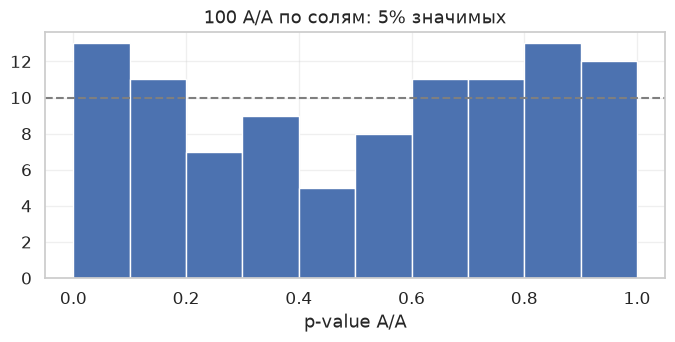

In [28]:
# @title Решение (нажмите, чтобы раскрыть)
aa_users = checkout[checkout['group'] == 'A'].sample(20_000, random_state=1)
aa_pvalues = []
for k in range(100):
    b = aa_users['user_id'].map(lambda u: assign_group(u, salt=f'aa_{k}') == 'B').to_numpy()
    y = aa_users['converted'].to_numpy()
    delta = y[b].mean() - y[~b].mean()
    se = np.sqrt(y[b].var() / b.sum() + y[~b].var() / (~b).sum())
    aa_pvalues.append(2 * stats.norm.sf(abs(delta / se)))
aa_pvalues = np.array(aa_pvalues)
aa_fpr = (aa_pvalues < 0.05).mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(aa_pvalues, bins=10, range=(0, 1), color=BLUE)
ax.axhline(10, color=GRAY, linestyle='--')
ax.set_xlabel('p-value A/A')
ax.set_title(f'100 A/A по солям: {aa_fpr:.0%} значимых')
plt.show()

In [29]:
# Проверка
assert len(aa_pvalues) == 100 and 0.0 <= aa_fpr <= 0.12, 'При исправном сплите доля значимых A/A около 5%'
assert stats.kstest(aa_pvalues, 'uniform').pvalue > 0.001, 'p-value A/A должны быть равномерны'
print(f'Д2 принято: {aa_fpr:.0%} значимых, KS p = {stats.kstest(aa_pvalues, "uniform").pvalue:.2f}')

Д2 принято: 5% значимых, KS p = 0.30
